In [1]:
from AnalysisDefinitions import AnalysisUltimate as AU
import matplotlib.pyplot as plt
import numpy as np

In [2]:
folder = 'Run_1670927963.hdf5'
ult = AU(h5_folder_path='DAQ_data/'+folder,single_file = True)

biases = list(ult.biases) #what biases to analyze
biases = sorted(list(biases))
print(ult.biases)
num_pes = [4,   5,   6,   6, 7] #the number of peaks to fit, ordered by bias in increasing order
pes_dict = {biases[i+1]: num_pes[i] for i in range(len(biases)-1)} #create a dictinoary. Can be manual: keys are biases, data is number of peaks as int
lowerlim = [45, 45, 45, 45, 50] #in mV #the lowerlims to be used, ordered by bias in increasing order
lowerlimdict = {biases[i+1]:lowerlim[i]/1000 for i in range(len(lowerlim))} #create a dictionary. Can be manual: keys are biases, data is lowerlim as float
pe_center_guesses = [52, 55, 70, 80, 95] #centers of the first pe, ordered by bias in increasing order
if pe_center_guesses:
    centers = {biases[i+1]: [pe_center_guesses[i] * peak / 1000 for peak in range(1,num_pes[i]+1)] for i in range(len(biases)-1)} #create a dictinoary. Can be manual: keys are biases, data is list of centers guesses for the multigaussian
invC = 0.011547 #inverse capacitance of pream-shaper circuit, see Noah's calibration report
invCerr = 0.000098 #error on above term

#print(biases)
uplims = {v:-1 for v in biases}
uplims[27] = 0.063
poly = {v:True for v in biases}
poly[27] = False
proms = {v:0.003  for v in biases}
proms[27] = 0.008

{np.float64(32.7): 'Acquisition_1670928125', np.float64(31.7): 'Acquisition_1670928422', np.float64(33.7): 'Acquisition_1670928767', np.float64(34.7): 'Acquisition_1670929047', np.float64(35.7): 'Acquisition_1670929275', np.float64(26.0): 'Acquisition_1670929481'}


In [3]:
ult.args_processwaveforms(do_filter=True,
                        prominence=proms,
                        condition = 'GN',
                        baseline_correct=True,
                        upper_limit=uplims,
                        poly_correct=poly)


In [4]:
ult.do_processwaveforms(temperature = 158,timeit=False,biases=biases)

Run Meta: {'CampaignIDNumber': '', 'RunName': 'SPE', 'RunNotes': '158K', 'RunStart': '1670927963', 'User': 'Hannah'}
{'AcquisitionEnd': '12/13/2022 11:05:11 AM',
 'AcquisitionMode': 'Fast',
 'AcquisitionNote': 'Solicited',
 'AcquisitionStart': '12/13/2022 11:04:41 AM',
 'Bias(V)': np.float64(26.0),
 'Duration(S)': np.uint16(5),
 'LowerLevel': np.float64(0.5),
 'Offset': np.float64(0.0),
 'OffsetTime': np.float64(6e-06),
 'Preamp': 'CR-Z-SiPM',
 'Quota': np.float64(2000.0),
 'Range': np.float64(1.0),
 'SampleTime': np.float64(0.0001),
 'Shaper': '<0>',
 'ShaperGain1': np.uint8(1),
 'ShaperGain2': np.uint8(0),
 'SlowControlUser': 'Hannah Peltz Smalley',
 'TemperatureMean': np.float64(nan),
 'TemperatureStdDev': np.float64(-0.0),
 'TriggerMode': 'Solicited',
 'TriggerSlope': 'Rising Edge',
 'TriggerSource': 'External Trigger Source',
 'Xe(g)': np.float64(94.49032253585499)}
filename: DAQ_data/Run_1670927963.hdf5, acquisition name: Acquisition_1670929481
using polynomial baseline correctio

c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret 

Run Meta: {'CampaignIDNumber': '', 'RunName': 'SPE', 'RunNotes': '158K', 'RunStart': '1670927963', 'User': 'Hannah'}
{'AcquisitionEnd': '12/13/2022 10:50:32 AM',
 'AcquisitionMode': 'Fast',
 'AcquisitionNote': '31.7 ',
 'AcquisitionStart': '12/13/2022 10:47:02 AM',
 'Bias(V)': np.float64(31.7),
 'Duration(S)': np.uint16(40),
 'LowerLevel': np.float64(0.075),
 'Offset': np.float64(0.42),
 'OffsetTime': np.float64(6e-06),
 'Preamp': 'CR-Z-SiPM',
 'Quota': np.float64(2000.0),
 'Range': np.float64(1.0),
 'SampleTime': np.float64(0.0001),
 'Shaper': '<0>',
 'ShaperGain1': np.uint8(1),
 'ShaperGain2': np.uint8(0),
 'SlowControlUser': 'Hannah Peltz Smalley',
 'TemperatureMean': np.float64(nan),
 'TemperatureStdDev': np.float64(-0.0),
 'TriggerMode': 'Self',
 'TriggerSlope': 'Rising Edge',
 'TriggerSource': 'Input Channel 1',
 'Xe(g)': np.float64(94.49032253585499)}
filename: DAQ_data/Run_1670927963.hdf5, acquisition name: Acquisition_1670928422
using polynomial baseline correction...
reading 

In [5]:
cutoffs = {}
for v in biases:
    if v <= 27:
        continue
    cutoffs[v] = (lowerlimdict[v], 1)
peak_ranges = {biases[i+1]: (1,num_pes[i]) for i in range(len(biases)-1)}

#centers = ult.guess_pe_locations(get_values=True,show_plots=True,cutoff=cutoffs)

ult.args_processhistograms(centers = centers, 
                        baseline_correct=True,
                        peaks='all',
                        cutoff=cutoffs,
                        background_linear=False,
                        peak_range=peak_ranges)

print(ult.measurementinfos)


ult.create_processhistograms()

print(ult.histograms)

{np.float64(31.7): <MeasurementInfo.MeasurementInfo object at 0x00000225ED8AC0D0>, np.float64(32.7): <MeasurementInfo.MeasurementInfo object at 0x00000225ED8AFF10>, np.float64(33.7): <MeasurementInfo.MeasurementInfo object at 0x00000225ED8AE890>, np.float64(34.7): <MeasurementInfo.MeasurementInfo object at 0x00000225ED8AC250>, np.float64(35.7): <MeasurementInfo.MeasurementInfo object at 0x00000225ED8AE8F0>, np.float64(26.0): 'not set'}
{np.float64(32.7): <ProcessHistograms.ProcessHist object at 0x00000225ED8AEB00>, np.float64(31.7): <ProcessHistograms.ProcessHist object at 0x00000225ED8AD4B0>, np.float64(33.7): <ProcessHistograms.ProcessHist object at 0x00000225ED8AF3A0>, np.float64(34.7): <ProcessHistograms.ProcessHist object at 0x00000225ED8AD1E0>, np.float64(35.7): <ProcessHistograms.ProcessHist object at 0x00000225ED8AFC10>}


In [6]:
#print(ult.histograms[32].get_spe())

In [7]:
ult.do_processhistograms()

CENTER GUESSES TO BE USED IN FIT:  [0.055, 0.11, 0.165, 0.22, 0.275]


c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')
c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')


sigma SNR: [np.float64(3.085011439217293), np.float64(2.9370183773657073), np.float64(2.693269871741301), np.float64(2.6957475805207705)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 1.0347839629033042 +/- 0.015144768917316405
CENTER GUESSES TO BE USED IN FIT:  [0.052, 0.104, 0.156, 0.208]
WARNING! Fitted sigma 0.012051414938875333 is less than baseline sigma 0.012581489111407107!
sigma SNR: [np.float64(2.7251856244164467), np.float64(2.7508267425410486), np.float64(2.6387208150330834)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 0.8256563249829427 +/- 0.05325405050619186
CENTER GUESSES TO BE USED IN FIT:  [0.07, 0.14, 0.21, 0.28, 0.35, 0.42]


c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')


WARNING! Fitted sigma 0.009132445038832556 is less than baseline sigma 0.012581489111407107!
sigma SNR: [np.float64(3.918013279586101), np.float64(3.8076214173398557), np.float64(3.5247499745659843), np.float64(3.466926084494859), np.float64(3.9731366439607503)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 1.4484672469592508 +/- 0.009238478596244609
CENTER GUESSES TO BE USED IN FIT:  [0.08, 0.16, 0.24, 0.32, 0.4, 0.48]


c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')


sigma SNR: [np.float64(4.455559863885971), np.float64(4.418886840170568), np.float64(4.242712322606269), np.float64(4.0983095240501894), np.float64(4.67816325280007)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 1.786207150063491 +/- 0.014903244822132886
CENTER GUESSES TO BE USED IN FIT:  [0.095, 0.19, 0.285, 0.38, 0.475, 0.57, 0.665]
sigma SNR: [np.float64(4.76229361907263), np.float64(4.195926908742537), np.float64(4.270485691495247), np.float64(3.8412733166714212), np.float64(3.8357098621352184), np.float64(5.036082884297325)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 1.9326548793029765 +/- 0.014655719370889489


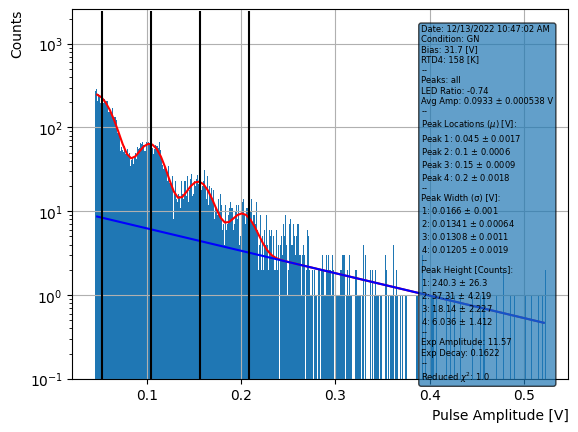

[0.052, 0.104, 0.156, 0.208]


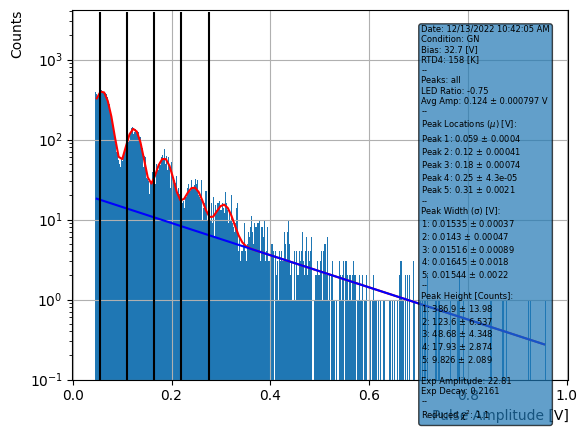

[0.055, 0.11, 0.165, 0.22, 0.275]


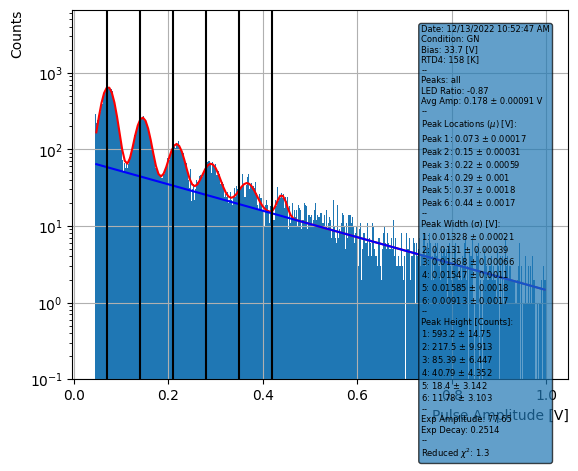

[0.07, 0.14, 0.21, 0.28, 0.35, 0.42]


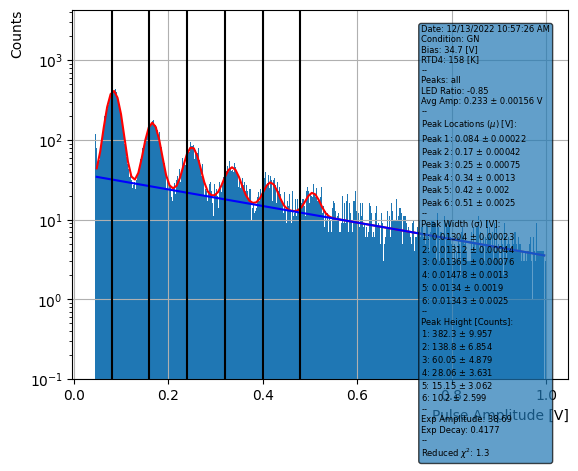

[0.08, 0.16, 0.24, 0.32, 0.4, 0.48]


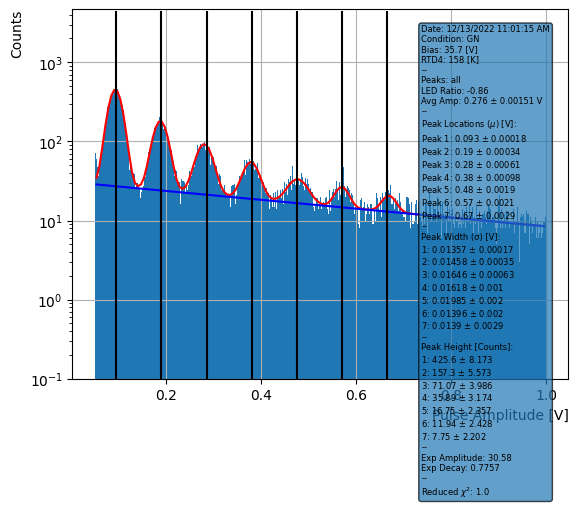

[0.095, 0.19, 0.285, 0.38, 0.475, 0.57, 0.665]


In [8]:
for bias in biases:
    if bias <= 27:
        continue
    ult.histograms[bias].plot_peak_histogram()
    print(ult.histograms[bias].centers)

In [9]:
#ult.histograms[35.7].centers = [.095*i for i in range(1,8)]
#ult.histograms[35.7].high_peak = 7
#ult.histograms[35.7].numpeaks = 7
#ult.histograms[35.7].peak_range = (1,7)
#ult.histograms[35.7].cutoff = (.05,1)
#ult.do_processhistograms(biases=[35.7])
#ult.histograms[35.7].plot_peak_histogram()

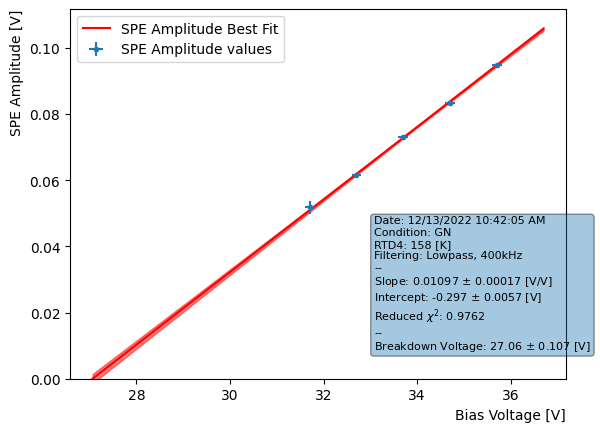

[0.06163529 0.05178246 0.07304485 0.08340514 0.09498822]


In [10]:
ult.do_spe_data(invC=invC,invC_err=invCerr,biases=biases)
ult.spe_data.plot_spe(in_ov=False,absolute=False)
print(ult.spe_data.spe_vals)